<a href="https://colab.research.google.com/github/hinojosaM/machine_learning_homework4/blob/main/machine_learning_homework4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [ ]:
# Try loading the dataset from the verified course repository paths
dataset_urls = [
    'https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv',
    'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring.csv',
    'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
]

df = None
for url in dataset_urls:
    try:
        df = pd.read_csv(url)
        print(f"Successfully loaded dataset from: {url}")
        break
    except Exception:
        continue

if df is None:
    raise FileNotFoundError("Could not download dataset from remote sources.")

print(f"Dataset shape: {df.shape}")

# Identify target and feature columns
target_col = 'converted'
feature_cols = [c for c in df.columns if c != target_col]

categorical = df[feature_cols].select_dtypes(include=['object', 'category']).columns.tolist()
numerical = df[feature_cols].select_dtypes(include=['number']).columns.tolist()

# Handle missing values as specified in the assignment:
# - Categorical features: replace with 'NA'
# - Numerical features: replace with 0.0
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

Successfully loaded dataset from: https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv
Dataset shape: (1462, 9)


In [ ]:
# Exact split calls required by the instructions
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Reset indices to keep everything cleanly aligned
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Separate target arrays
y_full_train = df_full_train[target_col].values
y_train = df_train[target_col].values
y_val = df_val[target_col].values
y_test = df_test[target_col].values

# Remove the target variable from feature sets
del df_full_train[target_col]
del df_train[target_col]
del df_val[target_col]
del df_test[target_col]

In [ ]:
print("QUESTION 1: Numerical Feature AUC on Training Set")


candidates_q1 = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

for col in candidates_q1:
    if col in df_train.columns:
        auc = roc_auc_score(y_train, df_train[col])
        # If negatively correlated (AUC < 0.5), invert the variable
        if auc < 0.5:
            auc = roc_auc_score(y_train, -df_train[col])
        print(f"Feature: {col:<26} | AUC: {auc:.4f}")

QUESTION 1: Numerical Feature AUC on Training Set
Feature: lead_score                 | AUC: 0.6145
Feature: number_of_courses_viewed   | AUC: 0.7636
Feature: interaction_count          | AUC: 0.7383
Feature: annual_income              | AUC: 0.5520


In [ ]:
# ------------------------------------------------------------------------------
print("QUESTION 2: Logistic Regression Validation AUC")

# One-hot encoding with DictVectorizer
dv = DictVectorizer(sparse=False)
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

# Train logistic regression with required hyperparameters
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=1)
model.fit(X_train, y_train)

# Predict probabilities and calculate validation AUC
y_pred_val = model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_pred_val)

print(f"Validation AUC (rounded to 3 decimals): {val_auc:.3f}")

QUESTION 2: Logistic Regression Validation AUC
Validation AUC (rounded to 3 decimals): 0.817


QUESTION 3: Precision-Recall Intersection
Intersection threshold: 0.64


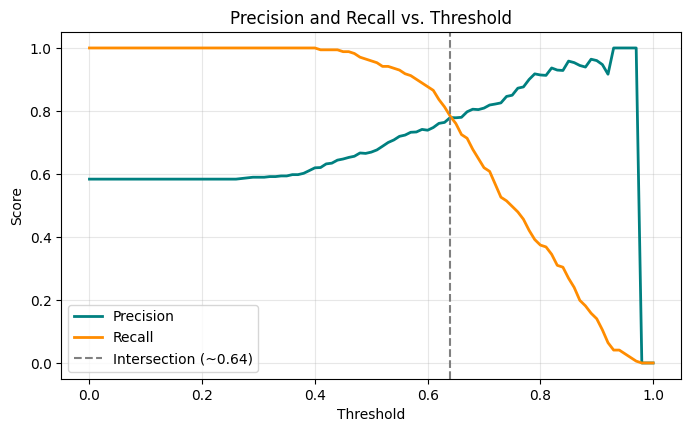

In [ ]:
print("QUESTION 3: Precision-Recall Intersection")


thresholds = np.linspace(0.0, 1.0, 101)
scores = []

for t in thresholds:
    actual_pos = (y_val == 1)
    actual_neg = (y_val == 0)
    pred_pos = (y_pred_val >= t)
    pred_neg = (y_pred_val < t)

    tp = (pred_pos & actual_pos).sum()
    tn = (pred_neg & actual_neg).sum()
    fp = (pred_pos & actual_neg).sum()
    fn = (pred_neg & actual_pos).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    scores.append((t, precision, recall))

df_pr = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

# Find the threshold where curves intersect (minimal absolute difference)
valid_pr = df_pr[(df_pr.precision > 0) | (df_pr.recall > 0)].copy()
valid_pr['diff'] = (valid_pr.precision - valid_pr.recall).abs()

best_threshold_pr = valid_pr.loc[valid_pr['diff'].idxmin(), 'threshold']
print(f"Intersection threshold: {best_threshold_pr:.2f}")

# Plot precision and recall
plt.figure(figsize=(8, 4.5))
plt.plot(df_pr.threshold, df_pr.precision, label='Precision', color='teal', lw=2)
plt.plot(df_pr.threshold, df_pr.recall, label='Recall', color='darkorange', lw=2)
plt.axvline(best_threshold_pr, color='gray', linestyle='--', label=f'Intersection (~{best_threshold_pr:.2f})')
plt.title('Precision and Recall vs. Threshold')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print("QUESTION 4: Threshold with Highest F1 Score")

# Compute F1: 2 * (P * R) / (P + R)
df_pr['f1'] = np.where(
    (df_pr.precision + df_pr.recall) > 0,
    2 * (df_pr.precision * df_pr.recall) / (df_pr.precision + df_pr.recall),
    0.0
)

best_f1_idx = df_pr['f1'].idxmax()
best_f1_row = df_pr.loc[best_f1_idx]

print(f"Peak F1 score: {best_f1_row['f1']:.4f}")
print(f"Optimal threshold for F1: {best_f1_row['threshold']:.2f}")

QUESTION 4: Threshold with Highest F1 Score
Peak F1 score: 0.8125
Optimal threshold for F1: 0.57


In [ ]:
print("QUESTION 5: 5-Fold Cross-Validation Standard Deviation")

def train_and_eval_fold(df_train_f, y_train_f, df_val_f, y_val_f, c_val=1.0):
    vec = DictVectorizer(sparse=False)
    X_tr = vec.fit_transform(df_train_f[categorical + numerical].to_dict(orient='records'))
    X_va = vec.transform(df_val_f[categorical + numerical].to_dict(orient='records'))

    clf = LogisticRegression(solver='liblinear', C=c_val, max_iter=1000, random_state=1)
    clf.fit(X_tr, y_train_f)

    probs = clf.predict_proba(X_va)[:, 1]
    return roc_auc_score(y_val_f, probs)

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
cv_scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    auc = train_and_eval_fold(
        df_full_train.iloc[train_idx], y_full_train[train_idx],
        df_full_train.iloc[val_idx], y_full_train[val_idx],
        c_val=1.0
    )
    cv_scores.append(auc)

print(f"Fold AUC scores: {[round(s, 4) for s in cv_scores]}")
print(f"Mean AUC: {np.mean(cv_scores):.3f}")
print(f"Standard Deviation (rounded to 3 decimals): {np.std(cv_scores):.3f}")

QUESTION 5: 5-Fold Cross-Validation Standard Deviation
Fold AUC scores: [np.float64(0.8061), np.float64(0.8714), np.float64(0.7754), np.float64(0.8018), np.float64(0.8558)]
Mean AUC: 0.822
Standard Deviation (rounded to 3 decimals): 0.036


In [ ]:
print("QUESTION 6: Hyperparameter Tuning for C")

c_candidates = [0.000001, 0.001, 1]
tuning_results = []

for c in c_candidates:
    scores_c = []
    for train_idx, val_idx in kfold.split(df_full_train):
        auc = train_and_eval_fold(
            df_full_train.iloc[train_idx], y_full_train[train_idx],
            df_full_train.iloc[val_idx], y_full_train[val_idx],
            c_val=c
        )
        scores_c.append(auc)

    mean_c = np.mean(scores_c)
    std_c = np.std(scores_c)
    tuning_results.append((c, mean_c, std_c))
    print(f"C = {c:<8} | Mean AUC: {mean_c:.3f} | Std: {std_c:.3f}")

# Tie-breaking rules from the course: highest mean, lowest std, smallest C
tuning_results.sort(key=lambda x: (-round(x[1], 3), round(x[2], 3), x[0]))
print(f"\nBest C parameter: {tuning_results[0][0]}")

QUESTION 6: Hyperparameter Tuning for C
C = 1e-06    | Mean AUC: 0.560 | Std: 0.024
C = 0.001    | Mean AUC: 0.867 | Std: 0.029
C = 1        | Mean AUC: 0.822 | Std: 0.036

Best C parameter: 0.001
